<a href="https://colab.research.google.com/github/JOJO002u/hello-world/blob/master/%E3%80%8C7820_project_ipynb%E3%80%8D%E7%9A%84%E5%89%AF%E6%9C%AC.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**1.Data Preparation**

1.1 Import libraries&load data

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files


uploaded = files.upload()
df = pd.read_csv('winequality-white.csv', sep=';')

Saving winequality-white.csv to winequality-white (1).csv


1.2 View missing values

In [ ]:
print(df.head())

print("\nData column name and type:\n", df.dtypes)

print("\nMissing value statistics:\n", df.isnull().sum())

   fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  \
0            7.0              0.27         0.36            20.7      0.045   
1            6.3              0.30         0.34             1.6      0.049   
2            8.1              0.28         0.40             6.9      0.050   
3            7.2              0.23         0.32             8.5      0.058   
4            7.2              0.23         0.32             8.5      0.058   

   free sulfur dioxide  total sulfur dioxide  density    pH  sulphates  \
0                 45.0                 170.0   1.0010  3.00       0.45   
1                 14.0                 132.0   0.9940  3.30       0.49   
2                 30.0                  97.0   0.9951  3.26       0.44   
3                 47.0                 186.0   0.9956  3.19       0.40   
4                 47.0                 186.0   0.9956  3.19       0.40   

   alcohol  quality  
0      8.8        6  
1      9.5        6  
2     10.1        6 

1.3 View duplicate value

In [ ]:
# Handle duplicates
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 937


In [ ]:
df = df.drop_duplicates()

In [ ]:
print("count of row:",df.count())

count of row: fixed acidity           3961
volatile acidity        3961
citric acid             3961
residual sugar          3961
chlorides               3961
free sulfur dioxide     3961
total sulfur dioxide    3961
density                 3961
pH                      3961
sulphates               3961
alcohol                 3961
quality                 3961
dtype: int64


1.4 Deal with outliers

In [ ]:
def remove_outliers_iqr(df):
    """
    使用IQR方法清洗所有数值型变量的异常值
    返回清洗后的数据框和删除的异常值数量
    """
    # 创建数据副本
    clean_df = df.copy()

    # 记录原始数据量
    original_count = len(clean_df)

    # 仅处理数值型列
    numeric_cols = clean_df.select_dtypes(include=['number']).columns

    for col in numeric_cols:
        # 计算四分位数
        Q1 = clean_df[col].quantile(0.25)
        Q3 = clean_df[col].quantile(0.75)
        IQR = Q3 - Q1

        # 设定异常值边界
        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR

        # 过滤异常值
        clean_df = clean_df[(clean_df[col] >= lower_bound)
                          & (clean_df[col] <= upper_bound)]

    # 计算删除数量
    removed_count = original_count - len(clean_df)

    return clean_df.reset_index(drop=True), removed_count

# 执行清洗
cleaned_df, removed = remove_outliers_iqr(df)

print(f"删除的异常值数量: {removed}")
print("清洗后的数据框:")
print(cleaned_df)

删除的异常值数量: 878
清洗后的数据框:
      fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  \
0               6.3              0.30         0.34             1.6      0.049   
1               8.1              0.28         0.40             6.9      0.050   
2               7.2              0.23         0.32             8.5      0.058   
3               6.2              0.32         0.16             7.0      0.045   
4               8.1              0.22         0.43             1.5      0.044   
...             ...               ...          ...             ...        ...   
3078            6.2              0.21         0.29             1.6      0.039   
3079            6.6              0.32         0.36             8.0      0.047   
3080            6.5              0.24         0.19             1.2      0.041   
3081            5.5              0.29         0.30             1.1      0.022   
3082            6.0              0.21         0.38             0.8      0.020   

    

Text(0.5, 1.02, 'Key Features vs Quality Relationship')

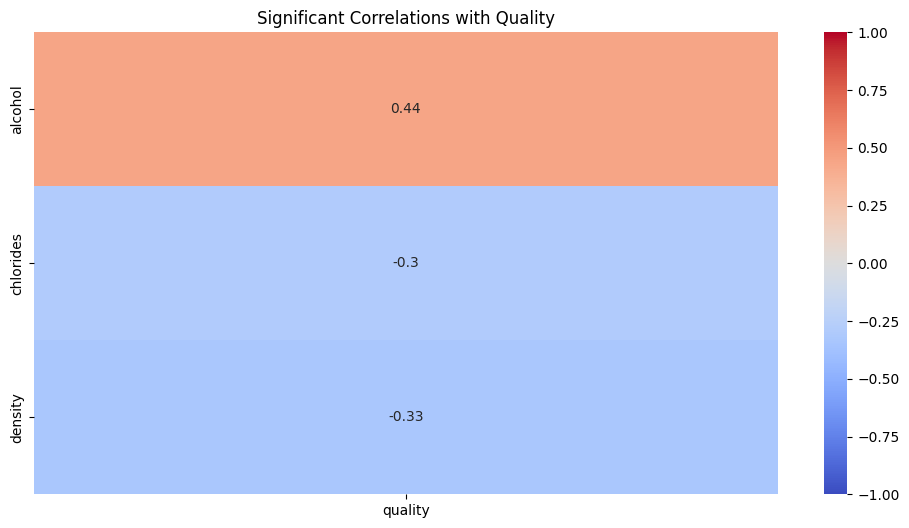

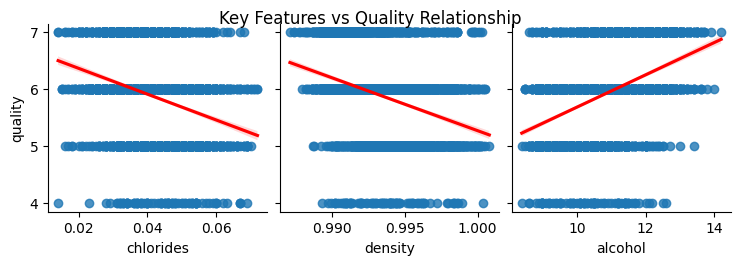

In [ ]:
import scipy.stats as stats

corr_matrix = cleaned_df.corr(method='pearson')
p_matrix = cleaned_df.corr(method=lambda x, y: stats.pearsonr(x, y)[1])

# 筛选与quality显著相关的指标
significant_features = []
for col in cleaned_df.columns:
    if col != 'quality' and abs(corr_matrix.loc[col, 'quality']) > 0.2 and p_matrix.loc[col, 'quality'] < 0.05:
        significant_features.append(col)

# 可视化
plt.figure(figsize=(12,6))
# 热力图
sns.heatmap(corr_matrix.loc[significant_features, ['quality']].sort_values(by='quality', ascending=False),
            annot=True, cmap='coolwarm', vmin=-1, vmax=1)
plt.title("Significant Correlations with Quality")

# 散点图矩阵
sns.pairplot(cleaned_df, x_vars=significant_features, y_vars=['quality'],
             kind='reg', plot_kws={'line_kws':{'color':'red'}})
plt.suptitle("Key Features vs Quality Relationship", y=1.02)

<ipython-input-79-b83bb0b3bbd8>:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  high_quality['ratio'] = high_quality['alcohol'] / high_quality['fixed acidity']
<ipython-input-79-b83bb0b3bbd8>:24: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  high_quality['cluster'] = kmeans.fit_predict(ratio_scaled.values.reshape(-1,1))


Text(0.5, 1.0, 'Alcohol/Acidity Ratio Distribution in High-Quality Wines')

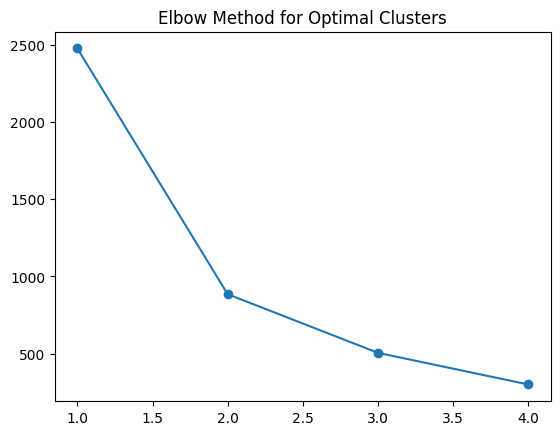

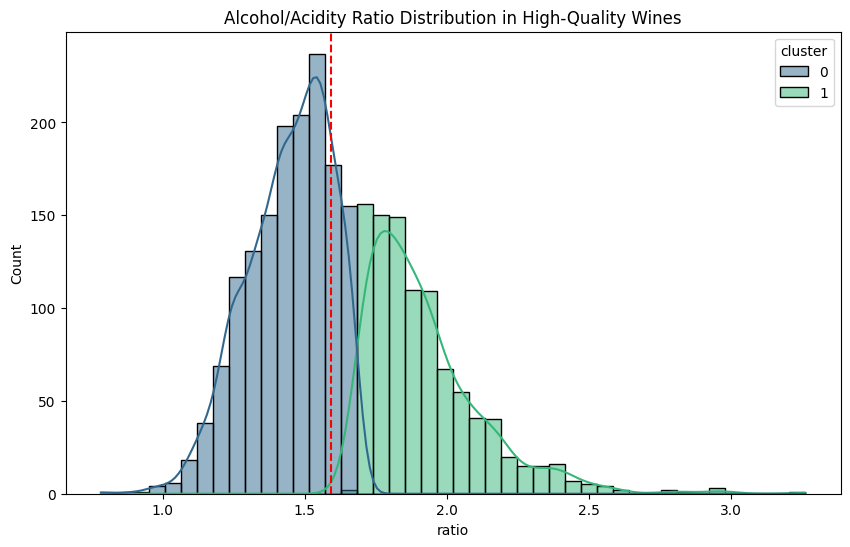

In [ ]:
from sklearn.cluster import KMeans

# 定义高评分样本（假设quality为1-10分）
high_quality = df[df['quality'] >= df['quality'].quantile(0.8)]

# 计算比值并标准化
high_quality['ratio'] = high_quality['alcohol'] / high_quality['fixed acidity']
ratio_scaled = (high_quality['ratio'] - high_quality['ratio'].mean()) / high_quality['ratio'].std()

# 寻找最优聚类
wcss = []
for i in range(1, 5):
    kmeans = KMeans(n_clusters=i, random_state=42)
    kmeans.fit(ratio_scaled.values.reshape(-1,1))
    wcss.append(kmeans.inertia_)

# 可视化肘部法则
plt.figure()
plt.plot(range(1,5), wcss, marker='o')
plt.title('Elbow Method for Optimal Clusters')

# 选择2个聚类进行分组
kmeans = KMeans(n_clusters=2, random_state=42)
high_quality['cluster'] = kmeans.fit_predict(ratio_scaled.values.reshape(-1,1))

# 绘制分布图
plt.figure(figsize=(10,6))
sns.histplot(data=high_quality, x='ratio', hue='cluster',
             palette='viridis', kde=True)
plt.axvline(x=high_quality['ratio'].median(), color='red', linestyle='--')
plt.title("Alcohol/Acidity Ratio Distribution in High-Quality Wines")

超标样本占比：0.00%
超标样本平均质量：nan vs 总体平均质量：5.8


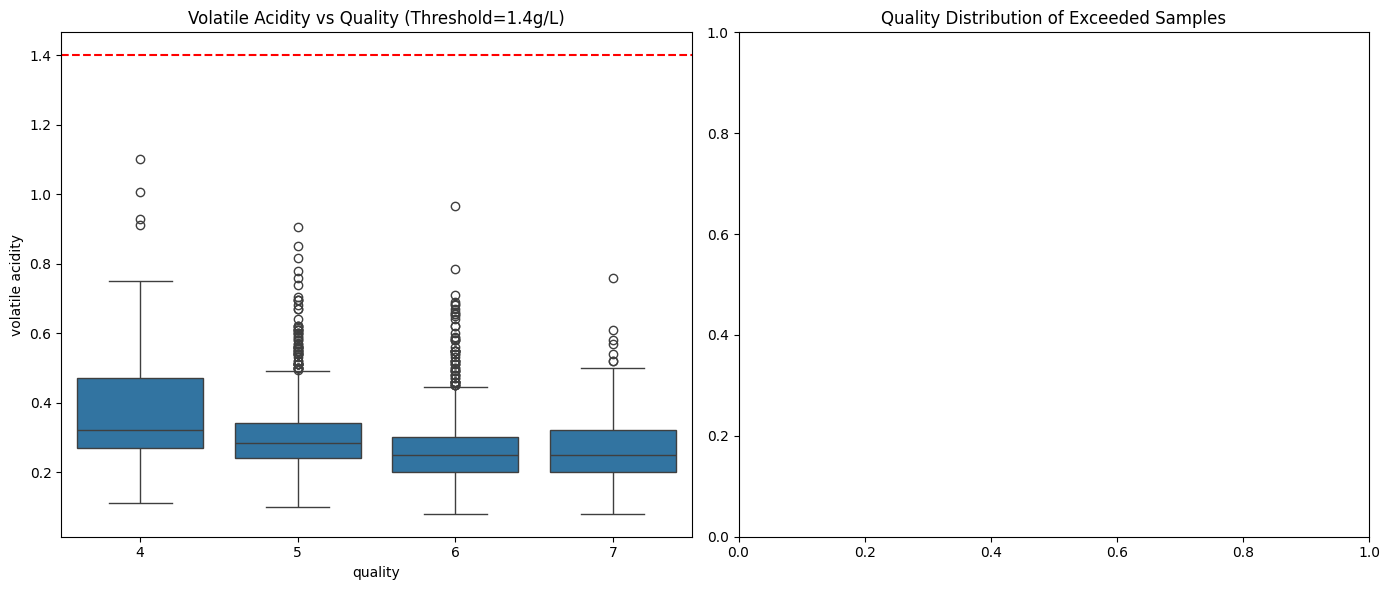

In [ ]:
# 设定安全阈值
va_threshold = 1.4  # 根据实际标准调整

# 统计超标样本
exceed_samples = df[df['volatile acidity'] > va_threshold]
exceed_rate = len(exceed_samples)/len(df)

# 可视化比较
fig, (ax1, ax2) = plt.subplots(1,2, figsize=(14,6))

# 阈值警示图
sns.boxplot(x='quality', y='volatile acidity', data=df, ax=ax1)
ax1.axhline(va_threshold, color='r', linestyle='--')
ax1.set_title(f"Volatile Acidity vs Quality (Threshold={va_threshold}g/L)")

# 超标样本质量分布
sns.countplot(x='quality', data=exceed_samples, ax=ax2, palette='Reds')
ax2.set_title("Quality Distribution of Exceeded Samples")
plt.tight_layout()

print(f"超标样本占比：{exceed_rate:.2%}")
print(f"超标样本平均质量：{exceed_samples['quality'].mean():.1f} vs 总体平均质量：{df['quality'].mean():.1f}")

In [ ]:
# 关键指标监控面板
metrics = {
    'Alcohol/Acidity Ratio': high_quality['ratio'].median(),
    'VA超标率': exceed_rate,
    '关键正相关指标': [f"{col}({corr_matrix.loc[col,'quality']:.2f})"
                    for col in significant_features if corr_matrix.loc[col,'quality']>0]
}
pd.DataFrame.from_dict(metrics, orient='index').style.background_gradient()

,0
Alcohol/Acidity Ratio,1.590909
VA超标率,0.000000
关键正相关指标,['alcohol(0.44)']


In [ ]:
# 基于国际通用标准定义口感分类（单位：g/L）
def classify_sweetness(rs):
    if rs < 4:
        return 'Dry'
    elif 4 <= rs < 12:
        return 'Off-Dry'
    elif 12 <= rs < 45:
        return 'Medium-Sweet'
    else:
        return 'Sweet'

df['sweetness'] = df['residual sugar'].apply(classify_sweetness)

<ipython-input-83-cad5c15cd1d0>:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x='sweetness', y='sugar_acid_ratio', data=df,


Text(0.5, 1.0, 'Sugar-Acid Ratio Distribution')

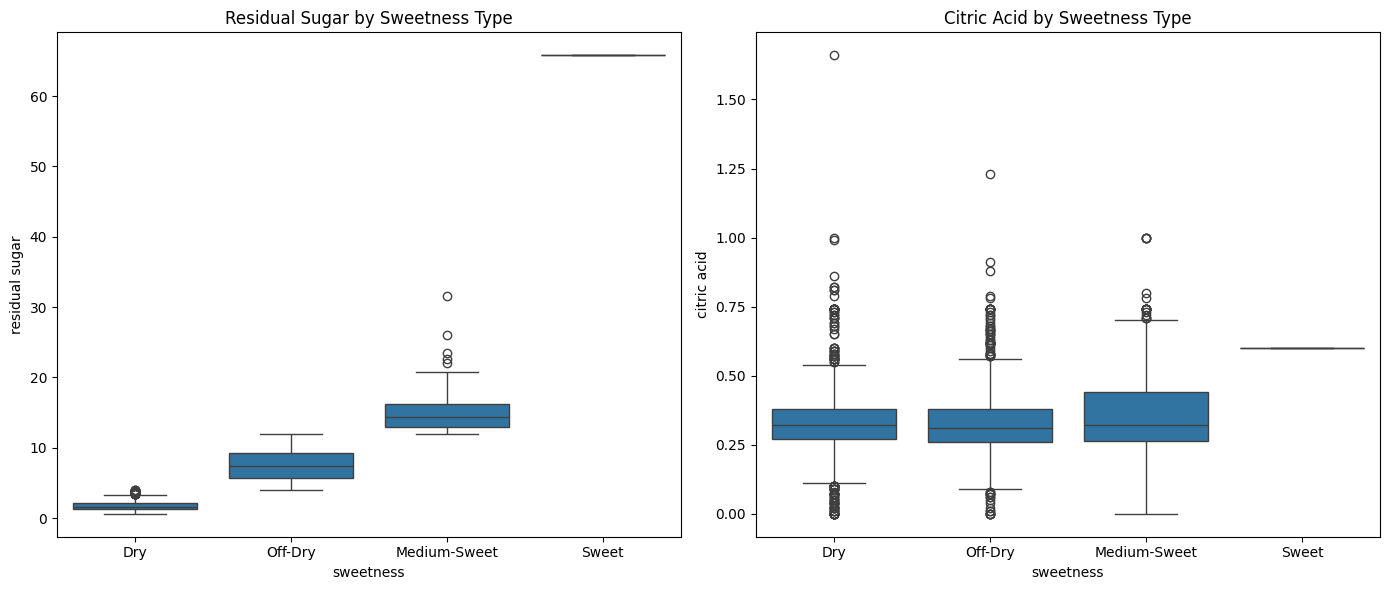

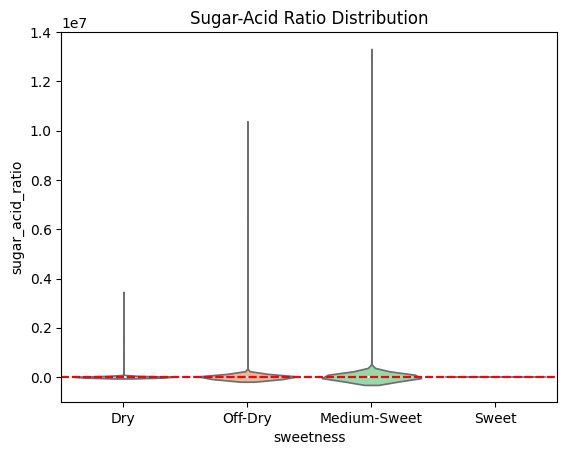

In [ ]:
# 计算糖酸比并标准化
df['sugar_acid_ratio'] = df['residual sugar'] / (df['citric acid'] + 1e-6)  # 防止除零

# 可视化不同口感类型的糖酸分布
plt.figure(figsize=(14,6))
plt.subplot(1,2,1)
sns.boxplot(x='sweetness', y='residual sugar', data=df, order=['Dry','Off-Dry','Medium-Sweet','Sweet'])
plt.title('Residual Sugar by Sweetness Type')

plt.subplot(1,2,2)
sns.boxplot(x='sweetness', y='citric acid', data=df, order=['Dry','Off-Dry','Medium-Sweet','Sweet'])
plt.title('Citric Acid by Sweetness Type')
plt.tight_layout()

# 糖酸比与口感类型关系
plt.figure()
sns.violinplot(x='sweetness', y='sugar_acid_ratio', data=df,
               order=['Dry','Off-Dry','Medium-Sweet','Sweet'], palette='pastel')
plt.axhline(y=df[df['sweetness']=='Dry']['sugar_acid_ratio'].median(), linestyle='--', color='blue')
plt.axhline(y=df[df['sweetness']=='Sweet']['sugar_acid_ratio'].median(), linestyle='--', color='red')
plt.title('Sugar-Acid Ratio Distribution')

Text(0.5, 1.0, 'High-Quality Wines: Sugar vs Acid Balance')

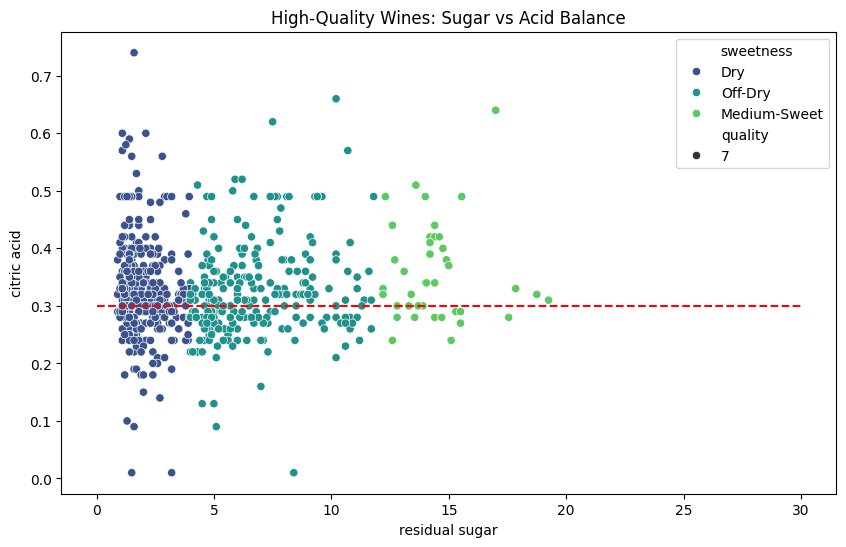

In [ ]:
# 寻找口感最佳的糖酸比区间（假设quality>=7为优质酒）
high_quality = df[df['quality'] >= 7]
plt.figure(figsize=(10,6))
sns.scatterplot(x='residual sugar', y='citric acid', hue='sweetness',
                style='quality', data=high_quality, palette='viridis')
plt.plot([0, 30], [0.3, 0.3], 'r--')  # 示例阈值线
plt.title('High-Quality Wines: Sugar vs Acid Balance')

In [ ]:
# IQR 法检测异常值
Q1 = cleaned_df['fixed acidity'].quantile(0.25)
Q3 = cleaned_df['fixed acidity'].quantile(0.75)
IQR = Q3 - Q1
outliers = cleaned_df[(cleaned_df['fixed acidity'] < Q1 - 1.5*IQR) | (cleaned_df['fixed acidity'] > Q3 + 1.5*IQR)]
print(outliers)

Empty DataFrame
Columns: [fixed acidity, volatile acidity, citric acid, residual sugar, chlorides, free sulfur dioxide, total sulfur dioxide, density, pH, sulphates, alcohol, quality]
Index: []


In [ ]:
# 创建矿物感综合指数（假设chlorides和pH权重相等）
df['minerality_index'] = 0.5*df['chlorides'] + 0.5*(1/df['pH'])  # pH取倒数（低pH增强矿物感）

Text(0.5, 1.0, 'Sulphates vs Minerality Index (r=-0.06)')

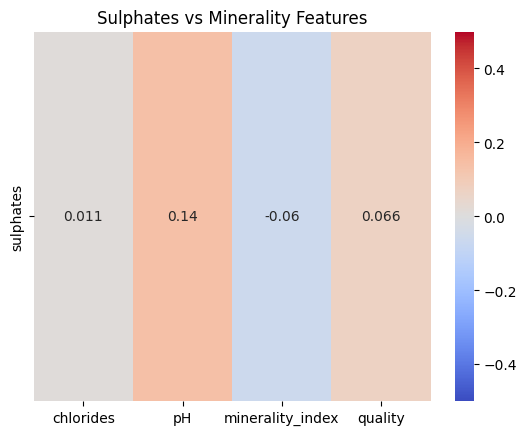

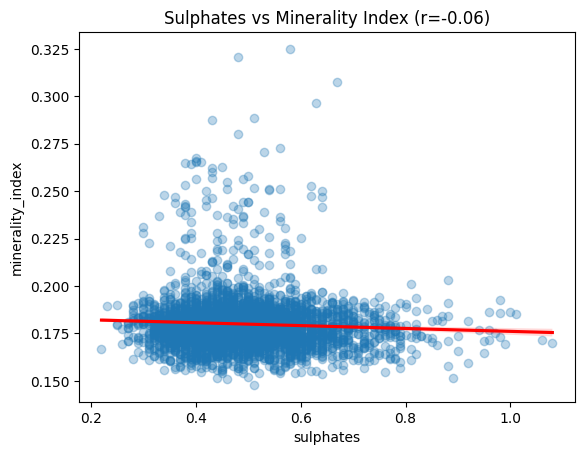

In [ ]:
# 计算硫酸盐与矿物感指标的相关性
minerality_features = ['sulphates', 'chlorides', 'pH', 'minerality_index']
corr = df[minerality_features + ['quality']].corr()

plt.figure()
sns.heatmap(corr.loc[['sulphates'], ['chlorides','pH','minerality_index','quality']],
            annot=True, cmap='coolwarm', vmin=-0.5, vmax=0.5)
plt.title('Sulphates vs Minerality Features')

# 硫酸盐与矿物感指数散点图
plt.figure()
sns.regplot(x='sulphates', y='minerality_index', data=df,
            scatter_kws={'alpha':0.3}, line_kws={'color':'red'})
plt.title(f'Sulphates vs Minerality Index (r={corr.loc["sulphates","minerality_index"]:.2f})')

Mann-Whitney U检验 p值=0.4273


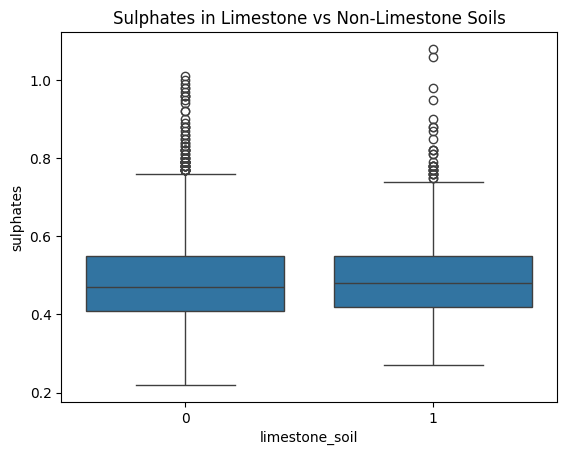

In [ ]:
# 假设有产区地质数据（示例：1=石灰岩土壤，0=其他）
import numpy as np
np.random.seed(42)
df['limestone_soil'] = np.random.choice([0,1], size=len(df), p=[0.7,0.3])

# 比较不同土壤类型的硫酸盐含量
plt.figure()
sns.boxplot(x='limestone_soil', y='sulphates', data=df)
plt.title('Sulphates in Limestone vs Non-Limestone Soils')

# 统计检验
from scipy.stats import mannwhitneyu
group1 = df[df['limestone_soil']==1]['sulphates']
group0 = df[df['limestone_soil']==0]['sulphates']
stat, p = mannwhitneyu(group1, group0)
print(f'Mann-Whitney U检验 p值={p:.4f}')

In [ ]:
df = df[(df['fixed acidity'] >= Q1 - 1.5*IQR) & (df['fixed acidity'] <= Q3 + 1.5*IQR)]
print(df.count())

fixed acidity           3855
volatile acidity        3855
citric acid             3855
residual sugar          3855
chlorides               3855
free sulfur dioxide     3855
total sulfur dioxide    3855
density                 3855
pH                      3855
sulphates               3855
alcohol                 3855
quality                 3855
dtype: int64


In [ ]:
Q1 = cleaned_df['volatile acidity'].quantile(0.25)
Q3 = cleaned_df['volatile acidity'].quantile(0.75)
IQR = Q3 - Q1
outliers = cleaned_df[(cleaned_df['volatile acidity'] < Q1 - 1.5*IQR) | (cleaned_df['volatile acidity'] > Q3 + 1.5*IQR)]
print(outliers)

      fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  \
112             7.6             0.480         0.37            0.80      0.037   
302             6.7             0.470         0.34            8.90      0.043   
460             6.2             0.470         0.21            1.00      0.044   
595             6.9             0.480         0.36            3.50      0.030   
660             7.1             0.470         0.24            6.00      0.044   
1251            8.6             0.485         0.29            4.10      0.026   
1384            7.6             0.480         0.28           10.40      0.049   
1443            7.6             0.480         0.33            7.00      0.024   
1760            6.7             0.480         0.32            1.40      0.021   
1771            6.8             0.475         0.33            3.95      0.047   
2146            6.7             0.470         0.29            4.75      0.034   
2208            6.2         

In [ ]:
df = df[(df['volatile acidity'] >= Q1 - 1.5*IQR) & (df['volatile acidity'] <= Q3 + 1.5*IQR)]
print(df.count())

fixed acidity           3698
volatile acidity        3698
citric acid             3698
residual sugar          3698
chlorides               3698
free sulfur dioxide     3698
total sulfur dioxide    3698
density                 3698
pH                      3698
sulphates               3698
alcohol                 3698
quality                 3698
dtype: int64


In [ ]:
Q1 = df['citric acid'].quantile(0.25)
Q3 = df['citric acid'].quantile(0.75)
IQR = Q3 - Q1
outliers = df[(df['citric acid'] < Q1 - 1.5*IQR) | (df['citric acid'] > Q3 + 1.5*IQR)]
print(outliers)

      fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  \
14              8.3              0.42         0.62           19.25      0.040   
16              6.3              0.48         0.04            1.10      0.046   
54              6.8              0.20         0.59            0.90      0.147   
62              7.0              0.47         0.07            1.10      0.035   
65              6.2              0.35         0.03            1.20      0.064   
...             ...               ...          ...             ...        ...   
4755            6.6              0.29         0.73            2.20      0.027   
4780            5.8              0.30         0.09            6.30      0.042   
4806            6.6              0.28         0.09           10.90      0.051   
4808            7.3              0.35         0.67            8.30      0.053   
4842            6.2              0.28         0.57            1.00      0.043   

      free sulfur dioxide  

In [ ]:
df = df[(df['citric acid'] >= Q1 - 1.5*IQR) & (df['citric acid'] <= Q3 + 1.5*IQR)]
print(df.count())

fixed acidity           3515
volatile acidity        3515
citric acid             3515
residual sugar          3515
chlorides               3515
free sulfur dioxide     3515
total sulfur dioxide    3515
density                 3515
pH                      3515
sulphates               3515
alcohol                 3515
quality                 3515
dtype: int64


In [ ]:
Q1 = df['residual sugar'].quantile(0.25)
Q3 = df['residual sugar'].quantile(0.75)
IQR = Q3 - Q1
outliers = df[(df['residual sugar'] < Q1 - 1.5*IQR) | (df['residual sugar'] > Q3 + 1.5*IQR)]
print(outliers)

      fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  \
0               7.0             0.270         0.36           20.70      0.045   
182             6.8             0.280         0.40           22.00      0.048   
261             6.9             0.290         0.40           19.45      0.043   
292             7.4             0.280         0.42           19.80      0.066   
444             6.9             0.240         0.36           20.80      0.031   
762             6.8             0.240         0.49           19.30      0.057   
1043            7.5             0.330         0.48           19.45      0.048   
1454            8.3             0.210         0.49           19.80      0.054   
1608            6.9             0.270         0.49           23.50      0.057   
1653            7.9             0.330         0.28           31.60      0.053   
2419            6.1             0.360         0.41           19.35      0.070   
2489            6.1         

In [ ]:
df = df[(df['residual sugar'] >= Q1 - 1.5*IQR) & (df['residual sugar'] <= Q3 + 1.5*IQR)]
print(df.count())

fixed acidity           3490
volatile acidity        3490
citric acid             3490
residual sugar          3490
chlorides               3490
free sulfur dioxide     3490
total sulfur dioxide    3490
density                 3490
pH                      3490
sulphates               3490
alcohol                 3490
quality                 3490
dtype: int64


In [ ]:
Q1 = df['free sulfur dioxide'].quantile(0.25)
Q3 = df['free sulfur dioxide'].quantile(0.75)
IQR = Q3 - Q1
outliers = df[(df['free sulfur dioxide'] < Q1 - 1.5*IQR) | (df['free sulfur dioxide'] > Q3 + 1.5*IQR)]
print(outliers)

      fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  \
67              6.7             0.250         0.13            1.20      0.041   
297             7.2             0.190         0.46            3.80      0.041   
325             7.5             0.270         0.31            5.80      0.057   
387             6.3             0.390         0.35            5.90      0.040   
395             6.8             0.270         0.12            1.30      0.040   
459             6.1             0.430         0.35            9.10      0.059   
484             6.2             0.370         0.30            6.60      0.346   
659             6.8             0.290         0.16            1.40      0.038   
752             6.7             0.200         0.42           14.00      0.038   
932             6.5             0.260         0.28           12.50      0.046   
1257            6.4             0.170         0.27            6.70      0.036   
1674            6.8         

In [ ]:
df = df[(df['free sulfur dioxide'] >= Q1 - 1.5*IQR) & (df['free sulfur dioxide'] <= Q3 + 1.5*IQR)]
print(df.count())

fixed acidity           3452
volatile acidity        3452
citric acid             3452
residual sugar          3452
chlorides               3452
free sulfur dioxide     3452
total sulfur dioxide    3452
density                 3452
pH                      3452
sulphates               3452
alcohol                 3452
quality                 3452
dtype: int64


In [ ]:
Q1 = df['total sulfur dioxide'].quantile(0.25)
Q3 = df['total sulfur dioxide'].quantile(0.75)
IQR = Q3 - Q1
outliers = df[(df['total sulfur dioxide'] < Q1 - 1.5*IQR) | (df['total sulfur dioxide'] > Q3 + 1.5*IQR)]
print(outliers)

      fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  \
111             7.2              0.27         0.46           18.75      0.052   
227             7.1              0.25         0.32           10.30      0.041   
746             7.0              0.21         0.34            8.50      0.033   
2434            8.3              0.28         0.27           17.50      0.045   
2654            6.9              0.40         0.22            5.95      0.081   
4514            6.1              0.40         0.18            9.00      0.051   

      free sulfur dioxide  total sulfur dioxide  density    pH  sulphates  \
111                  45.0                 255.0  1.00000  3.04       0.52   
227                  66.0                 272.0  0.99690  3.17       0.52   
746                  31.0                 253.0  0.99530  3.22       0.56   
2434                 48.0                 253.0  1.00014  3.02       0.56   
2654                 76.0                 303.0

In [ ]:
df = df[(df['total sulfur dioxide'] >= Q1 - 1.5*IQR) & (df['total sulfur dioxide'] <= Q3 + 1.5*IQR)]
print(df.count())

fixed acidity           3446
volatile acidity        3446
citric acid             3446
residual sugar          3446
chlorides               3446
free sulfur dioxide     3446
total sulfur dioxide    3446
density                 3446
pH                      3446
sulphates               3446
alcohol                 3446
quality                 3446
dtype: int64


In [ ]:
Q1 = df['density'].quantile(0.25)
Q3 = df['density'].quantile(0.75)
IQR = Q3 - Q1
outliers = df[(df['density'] < Q1 - 1.5*IQR) | (df['density'] > Q3 + 1.5*IQR)]
print(outliers)

      fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  \
1958            7.4              0.32         0.55            16.6      0.056   

      free sulfur dioxide  total sulfur dioxide  density    pH  sulphates  \
1958                 53.0                 238.0   1.0017  2.96       0.58   

      alcohol  quality  
1958      8.7        6  


In [ ]:
df = df[(df['density'] >= Q1 - 1.5*IQR) & (df['density'] <= Q3 + 1.5*IQR)]
print(df.count())

fixed acidity           3445
volatile acidity        3445
citric acid             3445
residual sugar          3445
chlorides               3445
free sulfur dioxide     3445
total sulfur dioxide    3445
density                 3445
pH                      3445
sulphates               3445
alcohol                 3445
quality                 3445
dtype: int64


In [ ]:
Q1 = df['pH'].quantile(0.25)
Q3 = df['pH'].quantile(0.75)
IQR = Q3 - Q1
outliers = df[(df['pH'] < Q1 - 1.5*IQR) | (df['pH'] > Q3 + 1.5*IQR)]
print(outliers)

      fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  \
72              6.0             0.270         0.28            4.80      0.063   
250             5.9             0.210         0.28            4.60      0.053   
320             6.0             0.100         0.24            1.10      0.041   
507             6.0             0.240         0.27            1.90      0.048   
830             7.3             0.205         0.31            1.70      0.060   
892             5.9             0.260         0.30            1.00      0.036   
928             6.5             0.250         0.35           12.00      0.055   
1014            6.1             0.160         0.27           12.60      0.064   
1095            5.3             0.240         0.33            1.30      0.033   
1250            5.3             0.260         0.23            5.15      0.034   
1255            6.4             0.220         0.34            1.80      0.057   
1335            5.7         

In [ ]:
df = df[(df['pH'] >= Q1 - 1.5*IQR) & (df['pH'] <= Q3 + 1.5*IQR)]
print(df.count())

fixed acidity           3396
volatile acidity        3396
citric acid             3396
residual sugar          3396
chlorides               3396
free sulfur dioxide     3396
total sulfur dioxide    3396
density                 3396
pH                      3396
sulphates               3396
alcohol                 3396
quality                 3396
dtype: int64


In [ ]:
Q1 = df['sulphates'].quantile(0.25)
Q3 = df['sulphates'].quantile(0.75)
IQR = Q3 - Q1
outliers = df[(df['sulphates'] < Q1 - 1.5*IQR) | (df['sulphates'] > Q3 + 1.5*IQR)]
print(outliers)

      fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  \
80              6.8              0.22         0.31             1.4      0.053   
154             8.2              0.23         0.40             7.5      0.049   
209             6.1              0.40         0.31             0.9      0.048   
245             6.1              0.18         0.36             2.0      0.038   
339             6.6              0.18         0.35             1.5      0.049   
...             ...               ...          ...             ...        ...   
4696            6.1              0.15         0.40             1.2      0.030   
4753            5.5              0.16         0.26             1.5      0.032   
4818            6.0              0.27         0.40             1.7      0.021   
4886            6.2              0.21         0.28             5.7      0.028   
4887            6.2              0.41         0.22             1.9      0.023   

      free sulfur dioxide  

In [ ]:
df = df[(df['sulphates'] >= Q1 - 1.5*IQR) & (df['sulphates'] <= Q3 + 1.5*IQR)]
print(df.count())

fixed acidity           3321
volatile acidity        3321
citric acid             3321
residual sugar          3321
chlorides               3321
free sulfur dioxide     3321
total sulfur dioxide    3321
density                 3321
pH                      3321
sulphates               3321
alcohol                 3321
quality                 3321
dtype: int64


In [ ]:
Q1 = df['alcohol'].quantile(0.25)
Q3 = df['alcohol'].quantile(0.75)
IQR = Q3 - Q1
outliers = df[(df['alcohol'] < Q1 - 1.5*IQR) | (df['alcohol'] > Q3 + 1.5*IQR)]
print(outliers)

Empty DataFrame
Columns: [fixed acidity, volatile acidity, citric acid, residual sugar, chlorides, free sulfur dioxide, total sulfur dioxide, density, pH, sulphates, alcohol, quality]
Index: []


In [ ]:
Q1 = df['quality'].quantile(0.25)
Q3 = df['quality'].quantile(0.75)
IQR = Q3 - Q1
outliers = df[(df['quality'] < Q1 - 1.5*IQR) | (df['quality'] > Q3 + 1.5*IQR)]
print(outliers)

Empty DataFrame
Columns: [fixed acidity, volatile acidity, citric acid, residual sugar, chlorides, free sulfur dioxide, total sulfur dioxide, density, pH, sulphates, alcohol, quality]
Index: []


In [ ]:
df = df[(df['quality'] >= Q1 - 1.5*IQR) & (df['quality'] <= Q3 + 1.5*IQR)]
print(df.count())

fixed acidity           3805
volatile acidity        3805
citric acid             3805
residual sugar          3805
chlorides               3805
free sulfur dioxide     3805
total sulfur dioxide    3805
density                 3805
pH                      3805
sulphates               3805
alcohol                 3805
quality                 3805
dtype: int64


**2. Exploratory Data Analysis**

2.1 Statistical Summary

In [ ]:
print(df.describe())

       fixed acidity  volatile acidity  citric acid  residual sugar  \
count    3961.000000       3961.000000  3961.000000     3961.000000   
mean        6.839346          0.280538     0.334332        5.914819   
std         0.866860          0.103437     0.122446        4.861646   
min         3.800000          0.080000     0.000000        0.600000   
25%         6.300000          0.210000     0.270000        1.600000   
50%         6.800000          0.260000     0.320000        4.700000   
75%         7.300000          0.330000     0.390000        8.900000   
max        14.200000          1.100000     1.660000       65.800000   

         chlorides  free sulfur dioxide  total sulfur dioxide      density  \
count  3961.000000          3961.000000           3961.000000  3961.000000   
mean      0.045905            34.889169            137.193512     0.993790   
std       0.023103            17.210021             43.129065     0.002905   
min       0.009000             2.000000         

2.2 Target Variable Distribution

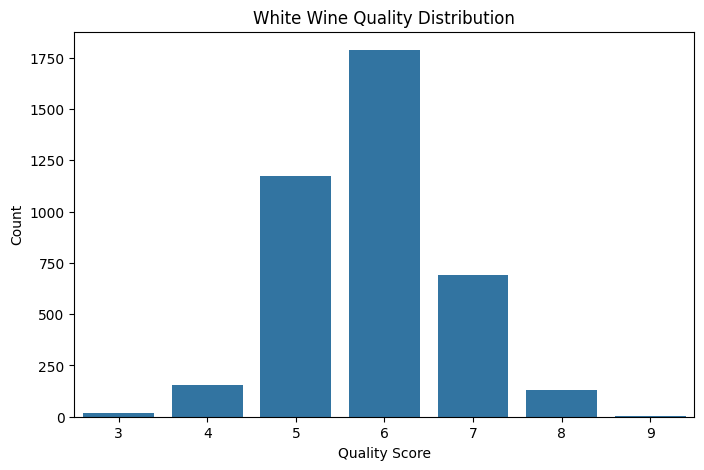

In [ ]:
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='quality')
plt.title('White Wine Quality Distribution')
plt.xlabel('Quality Score')
plt.ylabel('Count')
plt.show()

2.3 Correlation Analysis

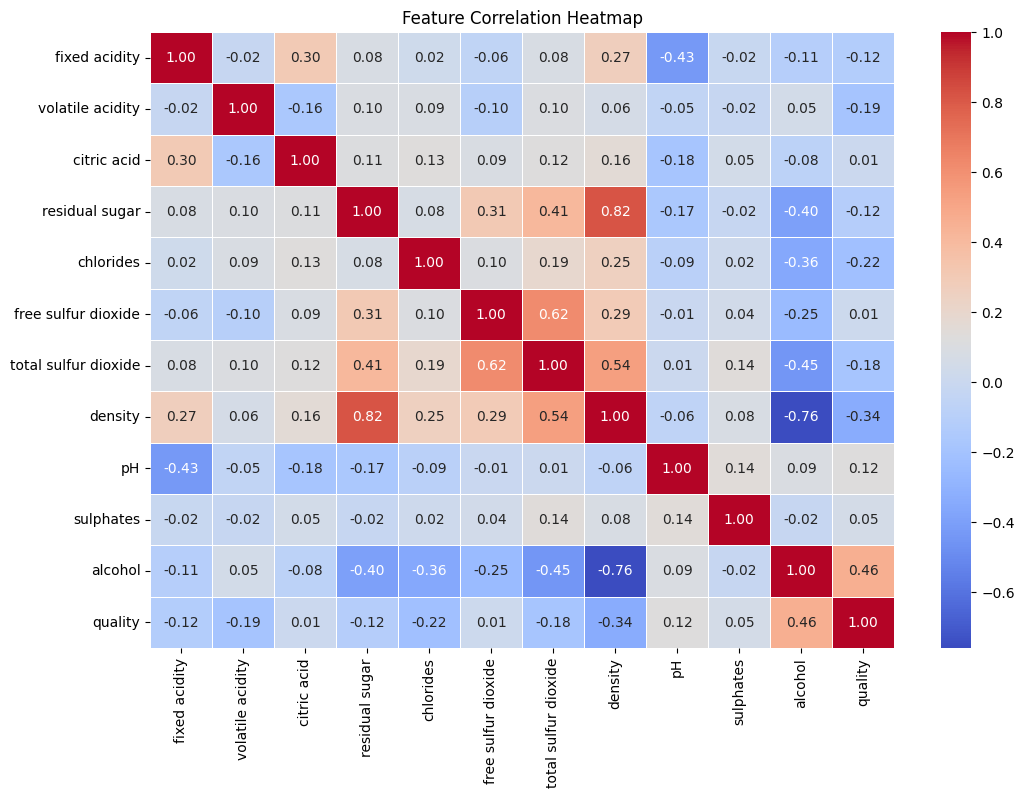


Quality Correlation Ranking:
 quality                 1.000000
alcohol                 0.462869
pH                      0.123829
sulphates               0.053200
free sulfur dioxide     0.010507
citric acid             0.007065
residual sugar         -0.117339
fixed acidity          -0.124636
total sulfur dioxide   -0.183356
volatile acidity       -0.190678
chlorides              -0.217739
density                -0.337805
Name: quality, dtype: float64


In [ ]:
# Correlation matrix
corr = df.corr()

# Heatmap visualization
plt.figure(figsize=(12, 8))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Feature Correlation Heatmap')
plt.show()

# Top correlations with quality
quality_corr = corr['quality'].sort_values(ascending=False)
print("\nQuality Correlation Ranking:\n", quality_corr)

**3. Key Relationships Visualization**

3.1 Alcohol vs Quality

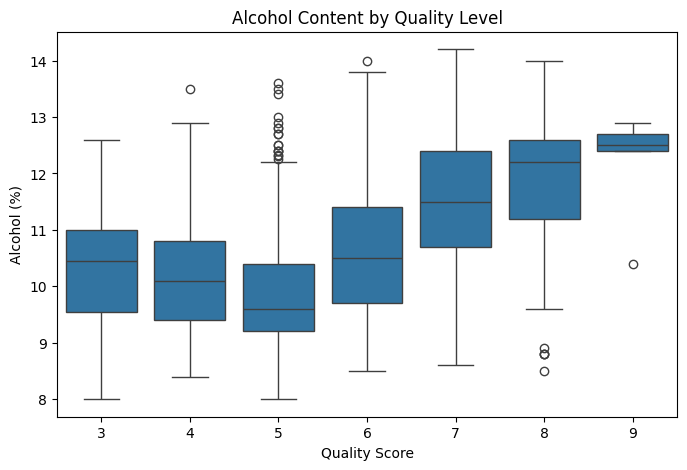

In [ ]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x='quality', y='alcohol')
plt.title('Alcohol Content by Quality Level')
plt.xlabel('Quality Score')
plt.ylabel('Alcohol (%)')
plt.show()

3.2 Volatile Acidity vs Quality

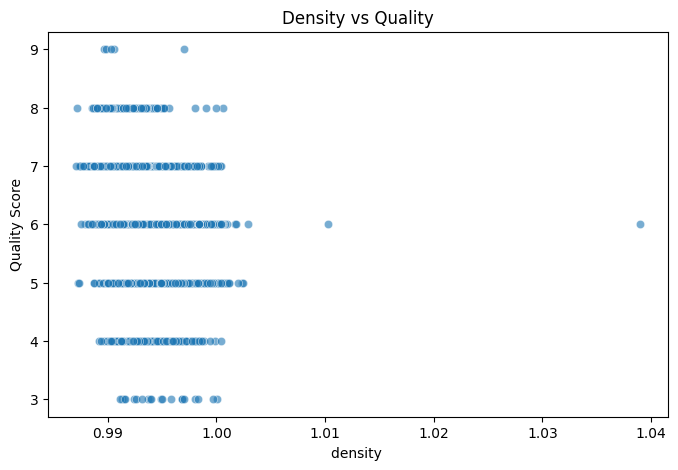

In [ ]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x='density', y='quality', alpha=0.6)
plt.title('Density vs Quality')
plt.xlabel('density ')
plt.ylabel('Quality Score')
plt.show()

3.3 Multivariate Analysis

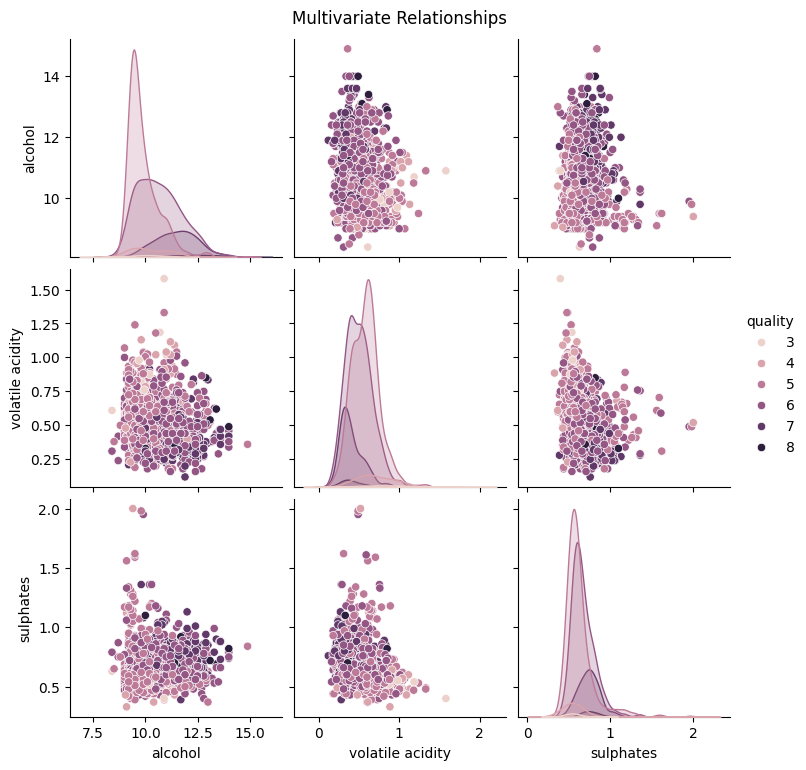

In [ ]:
sns.pairplot(df[['alcohol', 'volatile acidity', 'sulphates', 'quality']], hue='quality')
plt.suptitle('Multivariate Relationships', y=1.02)
plt.show()